# Section 4: Latent Traversal & Morphing Robot Video

Walk along a path in the learned 2D latent space, decode each waypoint into a robot
kinematic structure, and render the morphing sequence as an mp4. Reproduces paper Figure 3's
bottom interpolation strip (`rby1 → starred design`).

**Paper**: arXiv:2604.08636v1 §V-D: "Interpolating through the latent space reveals both
smooth morphing of link layouts and discrete changes like joint birth/death"

## What you get
- 2D latent path visualized on the 30-robot embedding
- mp4 of robot smoothly morphing along the path (joint birth/death visible as markers appear/disappear)
- Inline preview of 6 sample frames

## Safety
- `SAVE_OUTPUTS=False` default: frames in memory, no mp4 written
- `USE_LONG_PATH=False` default: 5-second / 75-frame demo (fast to run)
- Set `USE_LONG_PATH=True` for paper Fig 3-style 15-second cyclic traversal
- All mp4 / png writes go to `./outputs/`, never to canonical project folders

In [1]:
# ---- Tutorial flags ----
SAVE_OUTPUTS   = False    # if True, write mp4 + preview png to ./outputs/
USE_LONG_PATH  = False    # if True, render 15s cyclic spline through 8 waypoints (≈3 min CPU)
                          # if False, render 5s linear path between two latent points (≈1 min CPU)

# ---- Path setup ----
import os, sys
HERE = os.path.abspath('.')
REPO = os.path.abspath('../../')
for p in ['package','package/yoon','package/mujoco_helper','package/kinematics_helper',
          'package/utility','package/bvh_helper','package/smpl','package/motion_retarget',
          'package/irvae_tools','package/kinematics','asset']:
    sys.path.insert(0, os.path.join(REPO, p))

CANONICAL    = os.path.join(HERE, 'canonical/')
TUTORIAL_OUT = os.path.join(HERE, 'outputs/')
if SAVE_OUTPUTS:
    os.makedirs(TUTORIAL_OUT, exist_ok=True)

# RobotCharacteristics uses ../../asset/_robot_info/A-pose.json
os.chdir(os.path.join(REPO, 'notebook/ae_test'))

import numpy as np
import torch as th
import mujoco
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from tqdm.auto import tqdm

from data_utils import load_saved_model, load_data_subset
from clustering_robots import RobotCharacteristics

print(f'SAVE_OUTPUTS  = {SAVE_OUTPUTS}')
print(f'USE_LONG_PATH = {USE_LONG_PATH}')

~/anaconda3/envs/rilab/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SAVE_OUTPUTS  = False
USE_LONG_PATH = False


## 1. Load AE + robot_chars + encode 30 training robots

We need the AE to decode latent points, and an MJCF-rendering env (`RobotCharacteristics`) to
materialize each decoded design as a fresh robot.

In [2]:
repr_kind = 'screw'
model_name = 'h64_32_z2_isoTrue_actvTanh_isoreg1e-07_nepoch1000_bs10'

# Load AE
ae, _ = load_saved_model(model_name=model_name, device='cpu')
print(f'AE loaded: z_dim={ae.z_dim}')

# Load 30-robot data + encode
data_path = os.path.join(CANONICAL, 'data', repr_kind) + '/'
data = load_data_subset(data_path)
labels = np.load(os.path.join(CANONICAL, 'data', repr_kind, 'label.npy'))
names = [str(s) for s in labels]
with th.no_grad():
    z_all = ae.encode(th.tensor(data, dtype=th.float32)).numpy()
print(f'Encoded {len(z_all)} robots in latent space')

# Initialize robot_chars for MJCF rendering
robot_chars = RobotCharacteristics()
robot_chars.max_joints_per_group = np.load(os.path.join(CANONICAL, 'data', repr_kind, 'njnt.npy'))
print('robot_chars initialized')

AE loaded: z_dim=2
Encoded 30 robots in latent space
error in processing talos: not enough values to unpack (expected 2, got 0)
error in processing g1: not enough values to unpack (expected 2, got 0)
error in processing tiago_dual: not enough values to unpack (expected 2, got 0)
error in processing op3: not enough values to unpack (expected 2, got 0)
error in processing h1: not enough values to unpack (expected 2, got 0)
error in processing baxter: not enough values to unpack (expected 2, got 0)
error in processing digit: not enough values to unpack (expected 2, got 0)
error in processing ergocub: not enough values to unpack (expected 2, got 0)
error in processing alex: not enough values to unpack (expected 2, got 0)
error in processing pr2: not enough values to unpack (expected 2, got 0)
error in processing romeo: not enough values to unpack (expected 2, got 0)
error in processing icub: not enough values to unpack (expected 2, got 0)
error in processing jaxon: not enough values to unp

## 2. Build the latent path

Two modes (controlled by `USE_LONG_PATH` flag):

**Short (default)**: straight line from `rby1` (full humanoid, upper-left of latent space)
to `op3` (compact social humanoid, lower-right). 75 frames at 15 fps = 5 seconds.

**Long**: cyclic cubic-spline path through 8 max-distance waypoints. 450 frames at 30 fps =
15 seconds (matches paper Fig 3 strip aesthetic).

Linear path: rby1 → op3
latent_path shape: (75, 2)  (5s × 15fps = 75 frames)


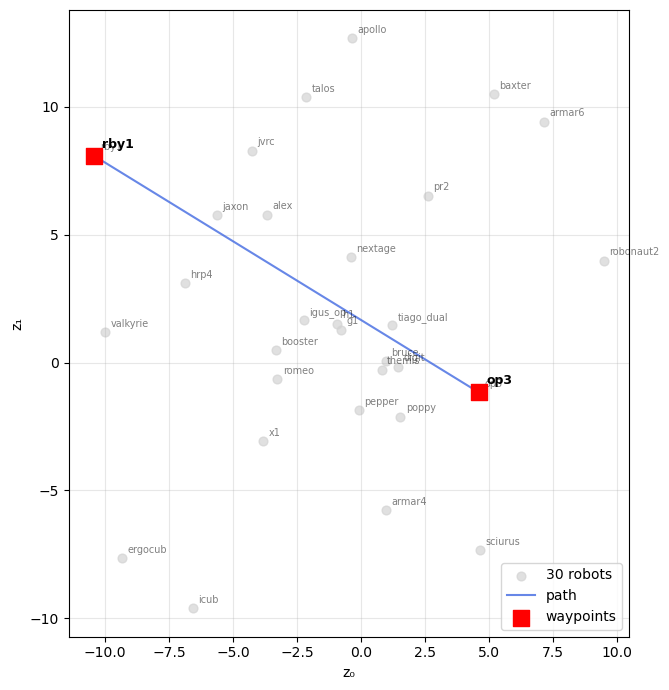

In [3]:
if USE_LONG_PATH:
    # === Long mode: cyclic spline through 8 max-distance waypoints ===
    FPS = 30
    DURATION_SEC = 15
    N_FRAMES = FPS * DURATION_SEC

    n_waypoints = 8
    selected = [0]
    for _ in range(n_waypoints - 1):
        dists = np.min(
            np.linalg.norm(z_all[:, None, :] - z_all[selected][None, :, :], axis=-1),
            axis=1)
        selected.append(int(np.argmax(dists)))
    waypoints = z_all[selected]
    waypoints = np.vstack([waypoints, waypoints[0]])  # close the loop

    t_wp = np.linspace(0, 1, len(waypoints))
    t_path = np.linspace(0, 1, N_FRAMES)
    cs = CubicSpline(t_wp, waypoints, bc_type='periodic')
    latent_path = cs(t_path)
    waypoint_names = [names[i] for i in selected]
    print(f'Selected waypoints: {waypoint_names}')
else:
    # === Short mode: straight line between two robots ===
    FPS = 15
    DURATION_SEC = 5
    N_FRAMES = FPS * DURATION_SEC

    start_robot = 'rby1'
    end_robot   = 'op3'
    i0 = names.index(start_robot)
    i1 = names.index(end_robot)
    t_path = np.linspace(0, 1, N_FRAMES)[:, None]
    latent_path = (1 - t_path) * z_all[i0] + t_path * z_all[i1]
    waypoints = z_all[[i0, i1]]
    waypoint_names = [start_robot, end_robot]
    print(f'Linear path: {start_robot} → {end_robot}')

print(f'latent_path shape: {latent_path.shape}  ({DURATION_SEC}s × {FPS}fps = {N_FRAMES} frames)')

# --- Visualize the path on 2D scatter ---
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(z_all[:, 0], z_all[:, 1], c='lightgray', s=40, alpha=0.7, label='30 robots')
ax.plot(latent_path[:, 0], latent_path[:, 1], '-', c='royalblue', lw=1.5, alpha=0.8, label='path')
ax.scatter(waypoints[:, 0], waypoints[:, 1], c='red', s=120, marker='s', zorder=5, label='waypoints')
for i, nm in enumerate(waypoint_names):
    ax.annotate(nm, waypoints[i], fontsize=9, fontweight='bold',
                xytext=(6, 6), textcoords='offset points')
# also label nearby robots faintly
for i, nm in enumerate(names):
    ax.annotate(nm, z_all[i], fontsize=7, alpha=0.5, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('z₀'); ax.set_ylabel('z₁')
ax.set_aspect('equal'); ax.grid(alpha=0.3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 3. Define the renderer

For each latent point along the path:
1. Decode → 120D screw vector
2. Build full 180D (mirror + threshold) → robot_data dict
3. Reconstruct kinematic chain + build MJCF spec
4. Forward kinematics, render offscreen with `mujoco.Renderer` → RGB frame

In [ ]:
def render_latent_path(
    robot_chars, model, latent_path, repr_kind='screw',
    width=1280, height=720,
    azimuth=170, distance=4.5, elevation=-15,
    lookat=None,
):
    """Render N frames along latent_path. Returns list of (H, W, 3) uint8 RGB arrays."""
    if lookat is None:
        lookat = [0.0, 0.0, 0.5]

    cam = mujoco.MjvCamera()
    cam.lookat[:] = lookat
    cam.distance, cam.azimuth, cam.elevation = distance, azimuth, elevation

    robot_chars._initialize_env()

    def render_frame(env):
        # offscreen render (no window); the buffer must be at least width x height
        env.model.vis.global_.offwidth  = max(width,  env.model.vis.global_.offwidth)
        env.model.vis.global_.offheight = max(height, env.model.vis.global_.offheight)
        renderer = mujoco.Renderer(env.model, height=height, width=width)
        renderer.update_scene(env.data, camera=cam)
        renderer.scene.flags[mujoco.mjtRndFlag.mjRND_SKYBOX] = False   # black sky
        img = renderer.render().copy()
        renderer.close()
        return img

    frames = []
    for z in tqdm(latent_path, desc='Rendering frames'):
        z_tensor = th.tensor(z[None, :], dtype=th.float32)
        with th.no_grad():
            half_data = model.decode(z_tensor).numpy()
        full_interp = robot_chars.build_full_interp_from_symmetric(
            interp_data_sym=half_data, threshold=0.0, repr_kind=repr_kind)
        robot_data = robot_chars.convert_flat_interp_to_dict(
            full_interp, threshold=0.5, repr_kind=repr_kind)['0']

        # Tear down + rebuild MJCF spec for this frame's design
        delete_list = []
        body = robot_chars.env.spec.worldbody.first_body()
        while body:
            delete_list.append(body)
            body = robot_chars.env.spec.worldbody.next_body(body)
        for body in delete_list:
            robot_chars.env.spec.detach_body(body)

        robot_chars.reconstruct_kinematic_chain('trial', robot_data=robot_data, repr_kind=repr_kind)
        robot_chars.env.forward(increase_tick=False)
        robot_chars.build_spec(robot_data, repr_kind=repr_kind)

        # build_spec compiles a new model every frame, so a new renderer is made for it
        robot_chars.env.forward(increase_tick=False)
        frames.append(render_frame(robot_chars.env))
    return frames

print('render_latent_path defined.')

## 4. Render the frames

Expected wall time:
- Short mode (75 frames): ~1 min
- Long mode (450 frames): ~3-5 min

In [5]:
import time
t0 = time.time()
frames = render_latent_path(
    robot_chars=robot_chars,
    model=ae,
    latent_path=latent_path,
    repr_kind=repr_kind,
    width=1280, height=720,
)
print(f'Rendered {len(frames)} frames in {time.time()-t0:.1f}s')
print(f'Frame shape: {frames[0].shape}')

ValueError: not enough values to unpack (expected 2, got 0)

## 5. Inline preview: 6 evenly-spaced frames

Quick visual sanity check before (optionally) writing the mp4.

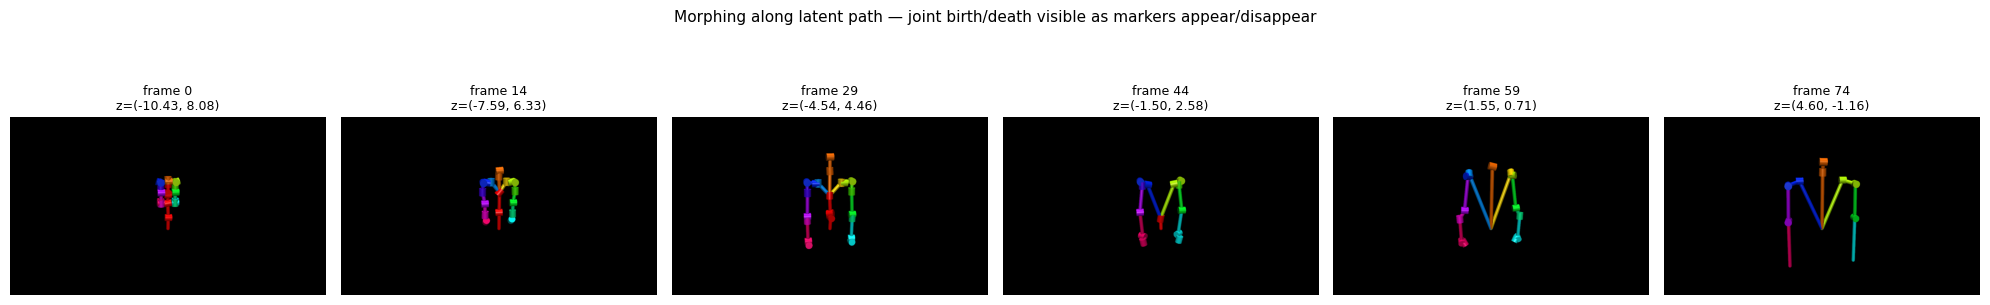

In [ ]:
n_preview = 6
idxs = np.linspace(0, len(frames) - 1, n_preview, dtype=int)
fig, axes = plt.subplots(1, n_preview, figsize=(20, 3.5))
for ax, idx in zip(axes, idxs):
    ax.imshow(frames[idx])
    z = latent_path[idx]
    ax.set_title(f'frame {idx}\nz=({z[0]:.2f}, {z[1]:.2f})', fontsize=9)
    ax.axis('off')
plt.suptitle('Morphing along latent path: joint birth/death visible as markers appear/disappear',
             y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

## 6. (Optional) Save mp4

If `SAVE_OUTPUTS=True`, encode the frames to mp4 in `outputs/`. Never writes to project canonical.

In [ ]:
if SAVE_OUTPUTS:
    from moviepy.editor import ImageSequenceClip
    suffix = 'long' if USE_LONG_PATH else 'short'
    out_mp4 = os.path.join(TUTORIAL_OUT, f'latent_traversal_{suffix}.mp4')
    clip = ImageSequenceClip(frames, fps=FPS)
    clip.write_videofile(out_mp4, codec='libx264', fps=FPS, logger=None)
    print(f'Saved: {out_mp4}  ({DURATION_SEC}s, {FPS}fps, {len(frames)} frames)')

    # Also save preview PNG
    out_png = os.path.join(TUTORIAL_OUT, f'latent_traversal_{suffix}_preview.png')
    fig, axes = plt.subplots(1, n_preview, figsize=(20, 3.5))
    for ax, idx in zip(axes, idxs):
        ax.imshow(frames[idx]); ax.axis('off')
    plt.tight_layout()
    plt.savefig(out_png, dpi=130, bbox_inches='tight')
    plt.close(fig)
    print(f'Saved: {out_png}')
else:
    print('SAVE_OUTPUTS=False: skipping. Set True to write mp4 + preview png to outputs/.')

SAVE_OUTPUTS=False: skipping. Set True to write mp4 + preview png to outputs/.


---

## Summary

- Built a latent path (linear or spline) through learned 2D design space
- Decoded each waypoint to a fresh MJCF robot via `build_full_interp_from_symmetric`
- Rendered frame-by-frame → mp4 of smoothly morphing robot structure
- Joint birth/death visible as markers appear/disappear (ε=0.5 activation threshold)

This is the visual proof of paper §V-D's claim that the **decoder's latent manifold is
both smooth and capable of discrete kinematic changes**.

**Related tutorials**:
- [`03_analysis_visualization.ipynb`](./03_analysis_visualization.ipynb): static cluster map
- [`05_retarget_to_designed_robot.ipynb`](./05_retarget_to_designed_robot.ipynb): make a decoded design execute a human motion